# 06 · Modelo de regresión · Objetivo 2 (predecir el tiempo de preparación)

## ¿Qué queremos conseguir?
Cuando entra un pedido en la cocina, queremos **estimar cuántos minutos tardará en estar listo**. En el notebook 05 vimos que el tiempo depende de cosas como los platos del pedido, la cola de cocina o los cocineros que hay. Ahora **construimos el primer modelo** que usa todo eso para predecir.

Un **modelo** es un programa que ha aprendido, a partir de miles de pedidos del pasado (en los que sabemos cuánto se tardó de verdad), a **dar una estimación para un pedido nuevo**. Esto es **aprendizaje supervisado** y, como la respuesta es un número (minutos), se llama **regresión**.

## ¿Qué hace este notebook?
Probamos **tres modelos** y los comparamos con una **línea base** (la predicción más simple posible):

| Prueba | Qué hace, en sencillo |
|---|---|
| **Línea base** | Dice siempre "25 minutos" (la media), sea cual sea el pedido. Es lo mínimo que hay que superar. |
| **Regresión lineal** | Calcula el tiempo **sumando** un tramo por cada característica del pedido (por ejemplo, "+2,5 min por plato"). Es sencillo y fácil de explicar. |
| **KNN (vecinos más cercanos)** | Para un pedido nuevo busca los **15 pedidos más parecidos** del pasado y **hace la media de sus tiempos**. Es muy intuitivo: "pedidos parecidos tardan parecido". |
| **Random Forest** | Un "bosque" de cientos de árboles de decisión que votan. Puede captar **curvas y combinaciones** (por ejemplo, que 10 pedidos en cola pesen distinto con 2 que con 7 cocineros). |

Todo lo que hacemos queda **registrado en MLflow** (parámetros, métricas, gráficos y el modelo), de modo que cada prueba se puede revisar y repetir. Cada ejecución y cada versión del modelo llevan la **fecha y la hora** en las que se entrenaron, para llevar un registro ordenado.

**Importante:**
- Es el **primer modelo** del proyecto: aceptamos que tenga fallos. **No creamos variables nuevas** y no ajustamos parámetros a mano; usamos las variables tal cual salen del notebook 02, con un único cambio de formato (pasar `canal` y `prioridad_aux` a columnas 0/1, explicado en la sección 3).
- Los datos son **sintéticos** (generados con un programa), así que los resultados serán más optimistas que en un restaurante real.

**Qué entrega:** el modelo ganador **registrado en MLflow** con el nombre `smart_restaurant_regresion_tiempo_prep` y el alias `actual`.

**Cómo ejecutarlo:** el servicio MLflow tiene que estar arrancado (`docker compose up -d` desde la carpeta `docker/`). Después, *Kernel → Restart & Run All*.

**Índice**
- Guía rápida de conceptos
- 0. Configuración y funciones
- 1. Conexión con MLflow y carga de datos
- 2. Separar entrenamiento y prueba
- 3. Preparar las variables
- 4. Los modelos que vamos a probar
- 5. Entrenar y registrar cada prueba en MLflow
- 6. Resultados: ¿superan los modelos a la línea base?
- 7. Mirando dentro de los modelos
- 8. Elegir el mejor y registrarlo
- 9. Cómo verlo en MLflow
- 10. Conclusiones

---
## Guía rápida de conceptos

| Concepto | Qué significa, en sencillo |
|---|---|
| **Entrenar un modelo** | Enseñarle pedidos pasados (con el tiempo real) para que aprenda qué características hacen que un pedido tarde más o menos. |
| **Variable objetivo (y)** | Lo que queremos predecir: `tiempo_prep_minutos`. |
| **Variables explicativas (X)** | Los datos del pedido que usa el modelo para predecir (platos, cola, cocineros, hora…). |
| **Entrenamiento y prueba** | Separamos los pedidos en dos partes: el modelo **aprende** con los más antiguos (80 %) y se le **examina** con los más recientes (20 %), que no ha visto nunca. Así sabemos cómo se portaría con pedidos futuros. |
| **Línea base** | La predicción más simple posible: decir siempre **la media** del tiempo de los pedidos de entrenamiento. Un modelo solo vale la pena si **la mejora claramente**. |
| **Regresión lineal** | Un modelo que **suma tramos**: tiempo = base + (minutos por plato × nº de platos) + (minutos por pedido en cola × cola) + … Cada característica aporta una cantidad fija. |
| **Árbol de decisión** | Una serie de preguntas de sí/no ("¿hay más de 8 pedidos en cola?", "¿es delivery?") que va dividiendo los pedidos hasta llegar a una estimación. |
| **KNN (K vecinos más cercanos)** | Para predecir un pedido, busca los **K pedidos de entrenamiento más parecidos** (los "vecinos") y **hace la media de sus tiempos**. Aquí K = 15. Mide el parecido con una distancia, así que antes hay que **poner todas las variables en la misma escala** (ver sección 3). |
| **Random Forest** | Muchos árboles de decisión, cada uno entrenado con una parte distinta de los datos. Para predecir, **cada árbol da su estimación y se hace la media**. Así los fallos de unos árboles se compensan con los de otros. |
| **Columnas 0/1 (*one-hot*)** | Los modelos no entienden texto. Una categoría como `canal` (mesa, delivery, takeaway) se convierte en columnas de 0 y 1: "¿es delivery? 1 / 0", "¿es takeaway? 1 / 0". Si las dos valen 0, es mesa. |
| **Escalar variables** | Cambiar las variables para que todas tengan un peso parecido (media 0 y dispersión 1). Sin esto, una variable con números grandes (la hora, de 0 a 24) pesaría más que una pequeña (0/1) solo por sus unidades. Solo lo necesita el KNN. |
| **Pipeline** | Una "cadena de montaje" que junta los pasos en un solo objeto: primero **preparar** las variables (pasar a 0/1, y escalar si hace falta) y después **predecir**. Así el modelo guardado ya sabe cómo preparar un pedido nuevo. |
| **Error (residuo)** | **Tiempo real − tiempo predicho**. Positivo: el modelo se quedó corto. Negativo: se pasó. |
| **MAE** | *Error absoluto medio*: de media, **cuántos minutos nos equivocamos**. Es la métrica más fácil de explicar. Más bajo = mejor. |
| **RMSE** | Parecido al MAE pero **castiga más los errores grandes**. Más bajo = mejor. Siempre es igual o mayor que el MAE. |
| **R²** | Qué parte de las diferencias entre pedidos explica el modelo. 0 = nada (como decir siempre la media); 1 = todo. |
| **Sobreajuste** | Cuando un modelo **memoriza** los pedidos de entrenamiento en vez de aprender reglas generales: acierta mucho con ellos y falla con pedidos nuevos. Se detecta comparando el error de entrenamiento con el de prueba. |
| **Importancia por permutación** | Para saber cuánto usa el modelo una variable, **la desordenamos al azar** y vemos cuánto empeora el MAE. Si empeora mucho, la variable es importante. |
| **MLflow** | El "cuaderno de laboratorio" del proyecto: guarda cada prueba (*run*) con sus **parámetros** (los ajustes), **métricas** (las notas), **artefactos** (gráficos y archivos) y el **modelo**. El *Model Registry* guarda los modelos con nombre y versión. |

---
## 0. Configuración y funciones

**Configuración:** todo lo que se puede cambiar (rutas, ajustes de los modelos, listas de columnas, colores) está **en una sola celda**. Si hay que cambiar algo, se cambia en un único sitio.

**Funciones:** "recetas" que se escriben una vez y se usan varias veces (por ejemplo, dibujar un gráfico o evaluar un modelo). Cada función lleva debajo, entre comillas, una descripción de lo que hace.

In [1]:
from __future__ import annotations   # permite usar list[str] o dict[str, float] en versiones antiguas de Python

import hashlib
import os
import warnings
from datetime import datetime
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# MLflow avisa de que las columnas enteras no admiten vacíos; nuestros datos no tienen vacíos, así que silenciamos el aviso
warnings.filterwarnings("ignore", message="Hint: Inferred schema contains integer column")

# ---------- Rutas: HDFS por WebHDFS (las variables de entorno las pone el contenedor de Docker) ----------
HOST = os.environ.get("HDFS_WEBHDFS_URL", "http://namenode:9870").replace("http://", "")
OPT = {"user": os.environ.get("HDFS_USER", "root")}
CLEAN = f"webhdfs://{HOST}/datalake/clean"
RUTA_PEDIDOS = f"{CLEAN}/pedidos_tiempos_preparacion/pedidos_limpio.parquet"   # ENTRADA: la deja el notebook 02

# ---------- MLflow ----------
MLFLOW_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://mlflow:5000")   # dirección del servidor MLflow
NOMBRE_EXPERIMENTO = "smart-restaurant-regresion-tiempo-prep"              # carpeta donde se agrupan las pruebas
NOMBRE_MODELO = "smart_restaurant_regresion_tiempo_prep"                   # nombre del modelo registrado
ALIAS_MODELO = "actual"                                                    # etiqueta que apunta a la versión vigente

# Marca de fecha y hora de ESTA ejecución (hora de España): se añade al nombre de cada ejecución y a cada versión del modelo en MLflow
MARCA_TIEMPO = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y-%m-%d_%H-%M")

# ---------- Datos y separación entrenamiento / prueba ----------
OBJETIVO = "tiempo_prep_minutos"           # lo que queremos predecir
FORMATO_FECHA = "%d-%m-%Y"                 # las fechas vienen como texto "día-mes-año"
FRACCION_ENTRENAMIENTO = 0.80              # el 80 % más antiguo para aprender; el 20 % más reciente para el examen
VARIABLES_NUMERICAS = ["n_platos", "num_platos_complejos", "complejidad_pedido", "cola_pedidos",
                       "cocineros_disponibles", "precipitacion_mm", "hora_dec", "dia_semana", "ingrediente_agotado"]
VARIABLES_CATEGORIA = ["canal", "prioridad_aux"]       # texto: se pasan a columnas 0/1 dentro del pipeline
VARIABLES = VARIABLES_NUMERICAS + VARIABLES_CATEGORIA  # todas las variables explicativas (X)
# Opciones de cada categoría. La PRIMERA es la de referencia (todo 0): mesa y normal.
OPCIONES_CATEGORIA = [["mesa", "delivery", "takeaway"], ["normal", "prioridad", "VIP"]]

# ---------- Ajustes de los modelos ----------
RANDOM_STATE = 42                          # el Random Forest usa azar; con la misma "semilla" sale siempre lo mismo
AJUSTES_RANDOM_FOREST = {
    "n_estimators": 200,                   # nº de árboles del bosque
    "min_samples_leaf": 5,                 # cada "hoja" del árbol debe agrupar al menos 5 pedidos (evita memorizar)
    "random_state": RANDOM_STATE,
    "n_jobs": -1,                          # usa todos los núcleos del ordenador para ir más rápido
}
AJUSTES_KNN = {
    "n_neighbors": 15,                     # K: nº de pedidos parecidos con los que se hace la media
}
MUESTRA_PERMUTACION = 5000                 # nº de pedidos de prueba que usamos para medir la importancia (más rápido)
REPETICIONES_PERMUTACION = 3               # cuántas veces desordenamos cada variable (se promedia)
TRAMOS_TIEMPO = [0, 20, 30, 40, 61]        # tramos del tiempo REAL para ver dónde falla cada modelo
ETIQUETAS_TRAMOS = ["menos de 20 min", "de 20 a 30 min", "de 30 a 40 min", "más de 40 min"]

# Nombre claro de cada variable para los gráficos
ETIQUETAS = {
    "n_platos": "nº de platos", "num_platos_complejos": "nº de platos complejos",
    "complejidad_pedido": "complejidad del pedido", "cola_pedidos": "pedidos en cola",
    "cocineros_disponibles": "cocineros disponibles", "precipitacion_mm": "lluvia (mm)",
    "hora_dec": "hora del día", "dia_semana": "día de la semana", "ingrediente_agotado": "ingrediente agotado",
    "canal": "canal", "prioridad_aux": "prioridad",
}

# ---------- Colores de Smart-Restaurant ----------
AZUL = "#1F3A44"          # azul petróleo
NARANJA = "#F28C38"
GRIS_AZULADO = "#5C808E"
MELOCOTON = "#FFE0C2"
CMAP_SEC = LinearSegmentedColormap.from_list("sr_sec", ["#FFFFFF", MELOCOTON, NARANJA, AZUL])   # de pocos a muchos pedidos
COLOR_MODELO = {"linea_base_media": GRIS_AZULADO, "regresion_lineal": NARANJA, "knn": "#6FA8A0", "random_forest": AZUL}
NOMBRE_LEGIBLE = {"linea_base_media": "línea base (la media)", "regresion_lineal": "regresión lineal", "knn": "KNN (15 vecinos)", "random_forest": "Random Forest"}

sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.edgecolor": GRIS_AZULADO, "axes.labelcolor": AZUL, "text.color": AZUL})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
def validar(condicion: bool, mensaje: str) -> None:
    """Comprueba algo que DEBE cumplirse. Si falla, el notebook se detiene con un mensaje claro."""
    assert condicion, f"FALLO: {mensaje}"
    print(f"OK · {mensaje}")


def conectar_mlflow(uri: str, nombre_experimento: str):
    """Conecta con el servidor MLflow y selecciona (o crea) el experimento. Falla rápido y con un mensaje claro."""
    try:
        requests.get(f"{uri}/health", timeout=5).raise_for_status()      # "ping" al servidor
    except Exception as error:
        raise RuntimeError(
            f"No se puede conectar con MLflow en {uri}. ¿Está arrancado el servicio? "
            "Desde la carpeta docker/ ejecuta: docker compose up -d --build") from error
    mlflow.set_tracking_uri(uri)
    return mlflow.set_experiment(nombre_experimento)


def fecha_de_corte(df: pd.DataFrame, fraccion: float = FRACCION_ENTRENAMIENTO) -> pd.Timestamp:
    """Devuelve el día a partir del cual los pedidos pasan a ser de "prueba" (el último 20 % cronológico)."""
    ordenado = df.sort_values(["fecha", "hora_dec"]).reset_index(drop=True)
    return ordenado.loc[int(len(ordenado) * fraccion), "fecha"]


def crear_preprocesado() -> ColumnTransformer:
    """Primer paso del pipeline: pasa `canal` y `prioridad_aux` a columnas 0/1 y deja el resto de variables tal cual.

    - Mesa y normal son las opciones de referencia (todo 0), así que cada columna 0/1 se lee como
      "diferencia frente a mesa / frente a normal".
    - Si en el futuro llega una opción desconocida, se deja todo a 0 en lugar de dar error.
    """
    codificador = OneHotEncoder(categories=OPCIONES_CATEGORIA, drop="first", handle_unknown="ignore")
    return ColumnTransformer([("categorias", codificador, VARIABLES_CATEGORIA)], remainder="passthrough")


def crear_pipeline(modelo, escalar: bool = False) -> Pipeline:
    """Junta en un solo objeto el preparado de variables y el modelo (así se guardan y se usan juntos).

    Con escalar=True añade un paso que pone todas las variables en la misma escala (media 0, dispersión 1).
    Lo necesita el KNN, que mide distancias entre pedidos; la regresión lineal y el Random Forest no.
    """
    pasos = [("preprocesado", crear_preprocesado())]
    if escalar:
        pasos.append(("escalado", StandardScaler()))
    return Pipeline(pasos + [("modelo", modelo)])


def evaluar(reales: pd.Series, predichos: np.ndarray) -> dict[str, float]:
    """Notas de un modelo: MAE y RMSE (en minutos, más bajo = mejor) y R² (más alto = mejor, máximo 1)."""
    return {
        "mae": float(mean_absolute_error(reales, predichos)),
        "rmse": float(np.sqrt(mean_squared_error(reales, predichos))),
        "r2": float(r2_score(reales, predichos)),
    }


def error_por_tramo(reales: pd.Series, predichos: np.ndarray) -> pd.DataFrame:
    """Dónde falla el modelo: agrupa los pedidos por su tiempo REAL y calcula, en cada tramo,
    el nº de pedidos, el MAE y el error medio con signo (real − predicho; positivo = el modelo se queda corto)."""
    tabla = pd.DataFrame({"tramo": pd.cut(reales, TRAMOS_TIEMPO, labels=ETIQUETAS_TRAMOS, right=False),
                          "error": reales.values - predichos})
    resumen = tabla.groupby("tramo", observed=True)["error"].agg(
        pedidos="size", mae=lambda e: e.abs().mean(), error_medio="mean")
    return resumen


def nombres_legibles(pipeline: Pipeline) -> list[str]:
    """Nombres claros de las columnas que recibe el modelo, tras pasar canal y prioridad a 0/1."""
    nombres = []
    for nombre in pipeline.named_steps["preprocesado"].get_feature_names_out():
        nombre = nombre.split("__", 1)[1]                      # quita el prefijo "categorias__" o "remainder__"
        for variable in VARIABLES_CATEGORIA:
            if nombre.startswith(variable + "_"):
                opcion = nombre[len(variable) + 1:]
                referencia = OPCIONES_CATEGORIA[VARIABLES_CATEGORIA.index(variable)][0]
                nombre = f"{ETIQUETAS[variable]} = {opcion} (frente a {referencia})"
        nombres.append(ETIQUETAS.get(nombre, nombre))
    return nombres


def importancia_permutacion(pipeline: Pipeline, X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """Cuánto empeora el MAE (en minutos) si desordenamos cada variable al azar. Más empeora = más importante.

    Se desordena la variable ORIGINAL (por ejemplo, `canal` entera), no cada columna 0/1 por separado.
    """
    muestra = X.sample(min(MUESTRA_PERMUTACION, len(X)), random_state=RANDOM_STATE).index
    resultado = permutation_importance(pipeline, X.loc[muestra], y.loc[muestra], scoring="neg_mean_absolute_error",
                                       n_repeats=REPETICIONES_PERMUTACION, random_state=RANDOM_STATE)
    tabla = pd.DataFrame({"variable": [ETIQUETAS[v] for v in X.columns],
                          "empeora_mae_min": resultado.importances_mean,
                          "desviacion": resultado.importances_std})
    return tabla.sort_values("empeora_mae_min", ascending=False).reset_index(drop=True)


def figura_real_vs_predicho(reales: pd.Series, predichos: np.ndarray, titulo: str) -> plt.Figure:
    """Gráfico de acierto: cada pedido de prueba es un punto. Eje x = minutos REALES; eje y = minutos PREDICHOS.

    El color indica cuántos pedidos hay en esa zona (más oscuro = más pedidos). La línea discontinua es la
    predicción perfecta: cuanto más pegada a ella esté la nube, mejor acierta el modelo.
    """
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    densidad = ax.hexbin(reales, predichos, gridsize=45, bins="log", cmap=CMAP_SEC, mincnt=1)
    ax.plot([3, 60], [3, 60], linestyle="--", color=GRIS_AZULADO, label="predicción perfecta")
    ax.set(title=titulo, xlabel="tiempo real (minutos)", ylabel="tiempo predicho (minutos)", xlim=(3, 60), ylim=(3, 60))
    ax.legend(loc="upper left", fontsize=8)
    fig.colorbar(densidad, ax=ax, label="nº de pedidos (escala logarítmica)")
    fig.tight_layout()
    return fig


def figura_errores(reales: pd.Series, predichos: np.ndarray, titulo: str) -> plt.Figure:
    """Histograma de los errores: eje x = error (real − predicho, en minutos); eje y = nº de pedidos.

    Lo ideal es una campana estrecha centrada en 0. A la derecha de 0 están los pedidos en los que el modelo se quedó corto.
    """
    fig, ax = plt.subplots(figsize=(5.2, 4.0))
    sns.histplot(reales.values - predichos, bins=60, color=AZUL, ax=ax)
    ax.axvline(0, color=NARANJA, linestyle="--", label="sin error")
    ax.set(title=titulo, xlabel="error = real − predicho (minutos)", ylabel="nº de pedidos")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def figura_importancia(tabla: pd.DataFrame, titulo: str, color: str = AZUL) -> plt.Figure:
    """Barras: eje y = variable; eje x = cuántos minutos empeora el MAE del modelo si esa variable se desordena."""
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    sns.barplot(data=tabla, y="variable", x="empeora_mae_min", color=color, ax=ax)
    ax.set(title=titulo, xlabel="minutos que empeora el MAE al desordenar la variable", ylabel="variable")
    fig.tight_layout()
    return fig


def figura_coeficientes(tabla: pd.DataFrame) -> plt.Figure:
    """Barras de la regresión lineal: eje y = variable; eje x = minutos que suma (o resta) el modelo
    por cada unidad más de esa variable (o, en las columnas 0/1, si la opción está presente)."""
    fig, ax = plt.subplots(figsize=(7.4, 4.6))
    colores = [NARANJA if c > 0 else AZUL for c in tabla["minutos"]]
    ax.barh(tabla["variable"], tabla["minutos"], color=colores)
    ax.axvline(0, color=GRIS_AZULADO, linewidth=0.8)
    ax.set(title="Regresión lineal: minutos que suma cada variable", xlabel="minutos por unidad (naranja = suma, azul = resta)", ylabel="variable")
    ax.invert_yaxis()
    fig.tight_layout()
    return fig


def figura_comparacion(tabla: pd.DataFrame) -> plt.Figure:
    """Barras agrupadas: para cada modelo, MAE y RMSE sobre los pedidos de PRUEBA (eje y = minutos; más bajo = mejor)."""
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    datos = tabla.reset_index().melt(id_vars="prueba", value_vars=["test_mae", "test_rmse"], var_name="nota", value_name="minutos")
    datos["nota"] = datos["nota"].map({"test_mae": "MAE (error medio)", "test_rmse": "RMSE (castiga errores grandes)"})
    datos["prueba"] = datos["prueba"].map(NOMBRE_LEGIBLE)
    sns.barplot(data=datos, x="prueba", y="minutos", hue="nota", palette=[AZUL, NARANJA], ax=ax)
    for barra in ax.patches:
        if barra.get_height() > 0:                       # saltamos las barras vacías (los huecos de la leyenda)
            ax.annotate(f"{barra.get_height():.1f}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        ha="center", va="bottom", fontsize=9)
    ax.set(title="Error de cada modelo con los pedidos de prueba", xlabel="modelo", ylabel="error (minutos)")
    ax.legend(title="")
    fig.tight_layout()
    return fig


def figura_tramos(tablas: dict[str, pd.DataFrame]) -> plt.Figure:
    """Barras agrupadas: eje x = tramo del tiempo REAL; eje y = MAE de cada modelo en ese tramo (minutos)."""
    datos = pd.concat({NOMBRE_LEGIBLE[n]: t["mae"] for n, t in tablas.items()}, names=["modelo"]).reset_index()
    fig, ax = plt.subplots(figsize=(8, 4.0))
    sns.barplot(data=datos, x="tramo", y="mae", hue="modelo", palette=[COLOR_MODELO[n] for n in tablas], ax=ax)
    ax.set(title="¿Dónde se equivoca más cada modelo?", xlabel="tiempo REAL del pedido", ylabel="MAE (minutos)")
    ax.legend(title="")
    fig.tight_layout()
    return fig

---
## 1. Conexión con MLflow y carga de datos

**Qué hacemos:** comprobamos que el servidor MLflow responde y seleccionamos nuestro experimento (si no existe, se crea). Después cargamos `pedidos_limpio.parquet`, la tabla de pedidos que dejó el notebook 02, y comprobamos con `validar(...)` lo que damos por supuesto. Si algo no se cumple, el notebook se para en esa celda.

In [3]:
# Conectamos con MLflow: si el servicio no está arrancado, aquí falla con un mensaje que explica qué hacer
experimento = conectar_mlflow(MLFLOW_URI, NOMBRE_EXPERIMENTO)
print(f"Servidor MLflow: {MLFLOW_URI}")
print(f"Experimento: {experimento.name} (id {experimento.experiment_id})")

Servidor MLflow: http://mlflow:5000
Experimento: smart-restaurant-regresion-tiempo-prep (id 2)


In [4]:
# Cargamos la tabla de pedidos (una fila por pedido)
pedidos = pd.read_parquet(RUTA_PEDIDOS, storage_options=OPT)
pedidos["fecha"] = pd.to_datetime(pedidos["fecha"], format=FORMATO_FECHA)     # texto -> fecha real

print(f"Pedidos: {len(pedidos):,} | Columnas: {pedidos.shape[1]}")
display(pedidos.head())

# Comprobaciones: cada línea afirma algo y falla si no es verdad
validar(all(c in pedidos.columns for c in VARIABLES + [OBJETIVO, "fecha"]), "están todas las columnas que necesita el modelo")
validar(int(pedidos[VARIABLES + [OBJETIVO]].isna().sum().sum()) == 0, "no hay celdas vacías en las variables ni en el objetivo")
validar(pedidos[OBJETIVO].between(3, 60).all(), "el tiempo de preparación está entre 3 y 60 minutos")
validar(bool(pedidos["fecha"].is_monotonic_increasing), "los pedidos están ordenados por fecha")
for variable, opciones in zip(VARIABLES_CATEGORIA, OPCIONES_CATEGORIA):
    validar(set(pedidos[variable].astype(str)) <= set(opciones), f"{variable} solo tiene las opciones esperadas: {opciones}")

Pedidos: 112,963 | Columnas: 13


,fecha,dia_semana,n_platos,complejidad_pedido,cola_pedidos,cocineros_disponibles,canal,prioridad_aux,num_platos_complejos,precipitacion_mm,ingrediente_agotado,hora_dec,tiempo_prep_minutos
0,2023-01-01,7,1,6.000,1,5,mesa,prioridad,0,0.000,0,10.120,11.000
1,2023-01-01,7,2,4.000,1,4,delivery,normal,0,0.000,0,10.530,15.000
2,2023-01-01,7,2,5.500,1,5,delivery,normal,1,0.000,0,11.370,17.600
3,2023-01-01,7,3,2.670,0,3,delivery,normal,0,0.000,0,11.570,18.600
4,2023-01-01,7,4,3.000,4,3,delivery,prioridad,0,0.000,0,11.600,25.300


OK · están todas las columnas que necesita el modelo
OK · no hay celdas vacías en las variables ni en el objetivo
OK · el tiempo de preparación está entre 3 y 60 minutos
OK · los pedidos están ordenados por fecha
OK · canal solo tiene las opciones esperadas: ['mesa', 'delivery', 'takeaway']
OK · prioridad_aux solo tiene las opciones esperadas: ['normal', 'prioridad', 'VIP']


---
## 2. Separar entrenamiento y prueba

**Qué hacemos:** dividimos los pedidos **por fecha**, como vimos en el notebook 05:
- **Entrenamiento (80 % más antiguo):** los pedidos con los que el modelo **aprende**.
- **Prueba (20 % más reciente):** los pedidos con los que lo **examinamos**. El modelo no los ve nunca al aprender.

**Por qué por fecha y no al azar:** en la vida real el modelo se usará para predecir pedidos **futuros**. Separar por fecha reproduce esa situación: aprende del pasado y se examina con "el futuro".

También calculamos una **huella** de los datos (un código corto que cambia si cambia cualquier valor), que se guarda en MLflow para saber con qué datos exactos se hizo cada prueba.

In [5]:
corte = fecha_de_corte(pedidos)
entrenamiento = pedidos[pedidos["fecha"] < corte]
prueba = pedidos[pedidos["fecha"] >= corte]

# X = las variables explicativas; y = lo que queremos predecir
X_entrenamiento, y_entrenamiento = entrenamiento[VARIABLES], entrenamiento[OBJETIVO]
X_prueba, y_prueba = prueba[VARIABLES], prueba[OBJETIVO]

validar(entrenamiento["fecha"].max() < prueba["fecha"].min(), "todo el entrenamiento es anterior a la prueba (ningún día en las dos partes)")
validar(len(entrenamiento) + len(prueba) == len(pedidos), "no se pierde ningún pedido al separar")

# Huella de los datos: si el parquet cambia, la huella cambia
huella_datos = hashlib.md5(pd.util.hash_pandas_object(pedidos[VARIABLES + [OBJETIVO]], index=False).values.tobytes()).hexdigest()[:12]

print(f"Entrenamiento: {len(entrenamiento):,} pedidos ({entrenamiento['fecha'].min():%d-%m-%Y} → {entrenamiento['fecha'].max():%d-%m-%Y})")
print(f"Prueba:        {len(prueba):,} pedidos ({prueba['fecha'].min():%d-%m-%Y} → {prueba['fecha'].max():%d-%m-%Y})")
print(f"Variables explicativas ({len(VARIABLES)}): {VARIABLES}")
print(f"Huella de los datos: {huella_datos}")

OK · todo el entrenamiento es anterior a la prueba (ningún día en las dos partes)
OK · no se pierde ningún pedido al separar
Entrenamiento: 90,300 pedidos (01-01-2023 → 04-06-2025)
Prueba:        22,663 pedidos (05-06-2025 → 31-12-2025)
Variables explicativas (11): ['n_platos', 'num_platos_complejos', 'complejidad_pedido', 'cola_pedidos', 'cocineros_disponibles', 'precipitacion_mm', 'hora_dec', 'dia_semana', 'ingrediente_agotado', 'canal', 'prioridad_aux']
Huella de los datos: c6ee6ba0c099


---
## 3. Preparar las variables

**Qué hacemos:** usamos las variables **tal cual** salen del notebook 02, con **un único cambio de formato**: `canal` y `prioridad_aux` son texto y los modelos solo entienden números, así que se pasan a **columnas de 0 y 1**.

**Ejemplo con `canal`** (mesa, delivery o takeaway) se convierte en dos columnas:

| canal | ¿es delivery? | ¿es takeaway? |
|---|---|---|
| mesa | 0 | 0 |
| delivery | 1 | 0 |
| takeaway | 0 | 1 |

"Mesa" no necesita columna propia: es la opción de **referencia** (las dos columnas valen 0). Lo mismo pasa con `prioridad_aux`, con "normal" como referencia.

**Es la misma información, solo cambia cómo se escribe.** No se crea ninguna variable nueva ni se combinan variables.

**Un paso extra solo para el KNN: escalar.** El KNN decide qué pedidos se "parecen" midiendo una **distancia**. Si las variables están en escalas muy distintas (la hora va de 0 a 24, pero una columna 0/1 solo de 0 a 1), la de números grandes **mandaría sin motivo**. Por eso, solo en el pipeline del KNN, se añade un paso (`StandardScaler`) que deja todas las variables con **media 0 y dispersión 1**. La regresión lineal y el Random Forest **no lo necesitan**, así que no se les aplica. Sigue sin cambiar la información, solo las unidades.

Este paso va **dentro del pipeline**, justo antes del modelo. Así, cuando llegue un pedido nuevo con `canal = "delivery"` escrito como texto, el modelo guardado sabe pasarlo a 0/1 por sí solo. Abajo comprobamos cómo queda la tabla que recibe el modelo.

In [6]:
# Aplicamos SOLO el paso de preparación a unos pocos pedidos para ver cómo queda lo que recibe el modelo
preprocesado_demo = crear_preprocesado().fit(X_entrenamiento)
columnas_modelo = nombres_legibles(Pipeline([("preprocesado", preprocesado_demo)]))
antes = X_entrenamiento[["canal", "prioridad_aux", "n_platos", "cola_pedidos"]].head(5)
despues = pd.DataFrame(preprocesado_demo.transform(X_entrenamiento.head(5)), columns=columnas_modelo)

print("ANTES (como salen del notebook 02):")
display(antes)
print(f"DESPUÉS (lo que recibe el modelo: {len(columnas_modelo)} columnas, todas numéricas):")
display(despues.iloc[:, :6])
print("Todas las columnas que recibe el modelo:", columnas_modelo)

ANTES (como salen del notebook 02):


,canal,prioridad_aux,n_platos,cola_pedidos
0,mesa,prioridad,1,1
1,delivery,normal,2,1
2,delivery,normal,2,1
3,delivery,normal,3,0
4,delivery,prioridad,4,4


DESPUÉS (lo que recibe el modelo: 13 columnas, todas numéricas):


,canal = delivery (frente a mesa),canal = takeaway (frente a mesa),prioridad = prioridad (frente a normal),prioridad = VIP (frente a normal),nº de platos,nº de platos complejos
0,0.000,0.000,1.000,0.000,1,0
1,1.000,0.000,0.000,0.000,2,0
2,1.000,0.000,0.000,0.000,2,1
3,1.000,0.000,0.000,0.000,3,0
4,1.000,0.000,1.000,0.000,4,0


Todas las columnas que recibe el modelo: ['canal = delivery (frente a mesa)', 'canal = takeaway (frente a mesa)', 'prioridad = prioridad (frente a normal)', 'prioridad = VIP (frente a normal)', 'nº de platos', 'nº de platos complejos', 'complejidad del pedido', 'pedidos en cola', 'cocineros disponibles', 'lluvia (mm)', 'hora del día', 'día de la semana', 'ingrediente agotado']


---
## 4. Los modelos que vamos a probar

Preparamos **tres modelos** y los comparamos con una **línea base**. Los tres reciben **exactamente los mismos datos** y se evalúan con **los mismos pedidos de prueba**, así que la comparación es justa.

0. **Línea base (`linea_base_media`):** no es un modelo, es **una cuenta**: calculamos la **media** del tiempo de los pedidos de entrenamiento y predecimos siempre ese número. No mira ninguna variable. Es la referencia mínima.
1. **Regresión lineal (`regresion_lineal`):** `LinearRegression`. Calcula un tiempo "base" y le suma (o resta) una cantidad fija por cada característica: por ejemplo, **+2,5 min por plato**. Es rápido y **fácil de interpretar**, pero solo capta relaciones en línea recta y **no** combinaciones entre variables.
2. **KNN (`knn`):** `KNeighborsRegressor`. Para cada pedido nuevo busca los **15 pedidos de entrenamiento más parecidos** (según todas sus variables, ya en la misma escala) y **hace la media de sus tiempos**. No aprende una fórmula: **recuerda los pedidos** y compara. Es muy fácil de explicar, pero es **más lento al predecir** (tiene que comparar con todos los pedidos guardados) y **el número de vecinos importa**: pocos vecinos = predicciones nerviosas; muchos = predicciones demasiado suaves.
3. **Random Forest (`random_forest`):** `RandomForestRegressor`. 200 árboles de decisión, cada uno entrenado con una parte distinta de los pedidos; para predecir se hace **la media de lo que dicen los 200**. Capta curvas y combinaciones (por ejemplo, la cola y los cocineros a la vez) **sin que tengamos que decirle cómo**.

**Ajustes** (en la celda de configuración): el KNN usa **15 vecinos**. En el Random Forest, 200 árboles y `min_samples_leaf = 5`, es decir, cada "hoja" de cada árbol debe agrupar al menos 5 pedidos para que el árbol no memorice casos sueltos. No hemos ajustado nada más: es una primera versión.

In [7]:
# Los tres modelos, cada uno dentro de su pipeline (preparar variables + predecir). El KNN lleva además el paso de escalado
MODELOS = {
    "regresion_lineal": crear_pipeline(LinearRegression()),
    "knn": crear_pipeline(KNeighborsRegressor(**AJUSTES_KNN), escalar=True),
    "random_forest": crear_pipeline(RandomForestRegressor(**AJUSTES_RANDOM_FOREST)),
}
for nombre, pipeline in MODELOS.items():
    print(f"{nombre:18s} -> {type(pipeline.named_steps['modelo']).__name__}")

regresion_lineal   -> LinearRegression
knn                -> KNeighborsRegressor
random_forest      -> RandomForestRegressor


---
## 5. Entrenar y registrar cada prueba en MLflow

**Qué hacemos:** para cada modelo: **entrenarlo**, **predecir** los pedidos de entrenamiento y de prueba, calcular las notas y **guardarlo todo en MLflow**.

**Cómo queda organizado en MLflow:**
- **Una ejecución padre** (`comparacion_modelos_<fecha>_<hora>`): contiene los datos comunes (fecha de corte, nº de pedidos, huella de los datos, variables), **las notas de la línea base** y los gráficos que comparan los modelos.
- **La fecha y la hora** de la ejecución van en el nombre de cada prueba, en una etiqueta (`fecha_ejecucion`) y en cada versión del modelo registrado, así sabemos siempre **cuándo** se entrenó cada cosa.
- **Tres ejecuciones hijas**, una por modelo (`regresion_lineal_<fecha>_<hora>`, `knn_<fecha>_<hora>` y `random_forest_<fecha>_<hora>`). Cada una guarda:
  - **Parámetros:** los ajustes del modelo.
  - **Métricas:** MAE, RMSE y R² en entrenamiento (`train_…`) y en prueba (`test_…`).
  - **Gráficos y tablas:** acierto, errores, error por tramo e importancia de las variables.
  - **El modelo** (el pipeline completo), con su *firma* (qué columnas espera) y un ejemplo de entrada.

**Por qué guardamos también las notas de entrenamiento:** si un modelo acierta mucho con los pedidos que ha visto (entrenamiento) y bastante menos con los nuevos (prueba), es señal de **sobreajuste**.

In [8]:
def ejecutar_prueba(nombre: str, pipeline: Pipeline) -> dict:
    """Entrena UN modelo, lo evalúa y lo guarda todo en MLflow como ejecución hija. Devuelve un resumen con los resultados."""
    with mlflow.start_run(run_name=f"{nombre}_{MARCA_TIEMPO}", nested=True) as ejecucion:
        mlflow.set_tag("fase", "comparacion")
        mlflow.set_tag("fecha_ejecucion", MARCA_TIEMPO)
        modelo = pipeline.named_steps["modelo"]

        # 1) Entrenar: el modelo aprende con los pedidos de entrenamiento
        pipeline.fit(X_entrenamiento, y_entrenamiento)

        # 2) Predecir y calcular las notas, con los pedidos de entrenamiento y con los de prueba
        pred_entrenamiento = pipeline.predict(X_entrenamiento)
        pred_prueba = pipeline.predict(X_prueba)
        metricas = {f"train_{k}": v for k, v in evaluar(y_entrenamiento, pred_entrenamiento).items()}
        metricas |= {f"test_{k}": v for k, v in evaluar(y_prueba, pred_prueba).items()}
        tramos = error_por_tramo(y_prueba, pred_prueba)
        importancia = importancia_permutacion(pipeline, X_prueba, y_prueba)

        # 3) Guardar en MLflow: parámetros, métricas, tablas y gráficos
        mlflow.log_params({"modelo": type(modelo).__name__, "variables": ",".join(VARIABLES),
                           "preprocesado": "canal y prioridad_aux a columnas 0/1 (referencia: mesa y normal)",
                           "escalado": "StandardScaler" if "escalado" in pipeline.named_steps else "no",
                           **{f"ajuste_{k}": v for k, v in modelo.get_params().items()}})
        mlflow.log_metrics(metricas)
        mlflow.log_text(tramos.round(4).to_csv(), "error_por_tramo.csv")
        mlflow.log_text(importancia.round(4).to_csv(index=False), "importancia_permutacion.csv")
        for figura, archivo in [(figura_real_vs_predicho(y_prueba, pred_prueba, NOMBRE_LEGIBLE[nombre]), "real_vs_predicho.png"),
                                (figura_errores(y_prueba, pred_prueba, NOMBRE_LEGIBLE[nombre]), "errores.png"),
                                (figura_importancia(importancia, NOMBRE_LEGIBLE[nombre], COLOR_MODELO[nombre]), "importancia_permutacion.png")]:
            mlflow.log_figure(figura, archivo)
            plt.close(figura)                      # lo cerramos para que no se dibuje aquí; lo mostramos más abajo

        # Solo la regresión lineal tiene "coeficientes" (los minutos que suma cada variable)
        coeficientes = None
        if isinstance(modelo, LinearRegression):
            coeficientes = pd.DataFrame({"variable": nombres_legibles(pipeline), "minutos": modelo.coef_})
            mlflow.log_param("minutos_base_intercepto", round(float(modelo.intercept_), 4))
            mlflow.log_text(coeficientes.round(4).to_csv(index=False), "coeficientes.csv")

        # 4) Guardar el modelo completo (pipeline) con su firma: qué columnas entran y qué sale
        firma = infer_signature(X_entrenamiento.head(100), pd.Series(pipeline.predict(X_entrenamiento.head(100)), name="tiempo_predicho"))
        info_modelo = mlflow.sklearn.log_model(pipeline, artifact_path="modelo", signature=firma,
                                               input_example=X_entrenamiento.head(3))

    return {"nombre": nombre, "run_id": ejecucion.info.run_id, "pipeline": pipeline, "metricas": metricas,
            "pred_prueba": pred_prueba, "tramos": tramos, "importancia": importancia,
            "coeficientes": coeficientes, "uri_modelo": info_modelo.model_uri}

In [9]:
# LÍNEA BASE: no es un modelo, es una cuenta. Predecimos siempre la media del tiempo de los pedidos de entrenamiento
media_entrenamiento = float(y_entrenamiento.mean())
pred_base_entrenamiento = np.full(len(y_entrenamiento), media_entrenamiento)
pred_base_prueba = np.full(len(y_prueba), media_entrenamiento)
metricas_base = {f"train_{k}": v for k, v in evaluar(y_entrenamiento, pred_base_entrenamiento).items()}
metricas_base |= {f"test_{k}": v for k, v in evaluar(y_prueba, pred_base_prueba).items()}
tramos_base = error_por_tramo(y_prueba, pred_base_prueba)
print(f"Línea base: predecir siempre {media_entrenamiento:.1f} minutos (la media del entrenamiento)")

resultados = {}
with mlflow.start_run(run_name=f"comparacion_modelos_{MARCA_TIEMPO}") as ejecucion_padre:
    mlflow.set_tag("fase", "comparacion")
    mlflow.set_tag("fecha_ejecucion", MARCA_TIEMPO)
    mlflow.log_params({
        "n_pedidos_entrenamiento": len(entrenamiento), "n_pedidos_prueba": len(prueba),
        "fecha_corte": f"{corte:%Y-%m-%d}", "variables": ",".join(VARIABLES),
        "huella_datos": huella_datos, "random_state": RANDOM_STATE,
        "linea_base_minutos": round(media_entrenamiento, 4),
    })
    mlflow.log_metrics({f"linea_base_{k}": v for k, v in metricas_base.items()})   # notas de la línea base

    # Una ejecución hija por modelo
    for nombre, pipeline in MODELOS.items():
        resultados[nombre] = ejecutar_prueba(nombre, pipeline)
        print(f"{nombre:18s} listo · MAE en prueba = {resultados[nombre]['metricas']['test_mae']:.2f} min")

    # Gráficos que comparan los modelos (se guardan en la ejecución padre)
    tabla_notas = pd.DataFrame({"linea_base_media": metricas_base, **{n: r["metricas"] for n, r in resultados.items()}}).T
    tabla_notas.index.name = "prueba"
    fig_comparacion = figura_comparacion(tabla_notas)
    fig_tramos = figura_tramos({"linea_base_media": tramos_base, **{n: r["tramos"] for n, r in resultados.items()}})
    mlflow.log_figure(fig_comparacion, "comparacion_modelos.png")
    mlflow.log_figure(fig_tramos, "error_por_tramo.png")
    mlflow.log_text(tabla_notas.round(4).to_csv(), "notas_modelos.csv")
    plt.close(fig_comparacion)
    plt.close(fig_tramos)

print(f"\nSe han registrado {len(resultados)} pruebas en MLflow (más la ejecución padre).")

Línea base: predecir siempre 25.3 minutos (la media del entrenamiento)
🏃 View run regresion_lineal_2026-11-25_09-55 at: http://mlflow:5000/#/experiments/2/runs/60eaed7539c84db399ae2ddf5b4c0c45
🧪 View experiment at: http://mlflow:5000/#/experiments/2
regresion_lineal   listo · MAE en prueba = 2.36 min
🏃 View run knn_2026-11-25_09-55 at: http://mlflow:5000/#/experiments/2/runs/cc102dd581804b7f8647cef7bfd4e991
🧪 View experiment at: http://mlflow:5000/#/experiments/2
knn                listo · MAE en prueba = 2.45 min
🏃 View run random_forest_2026-11-25_09-55 at: http://mlflow:5000/#/experiments/2/runs/db78b499a2e54288ac84b7b650ecf692
🧪 View experiment at: http://mlflow:5000/#/experiments/2
random_forest      listo · MAE en prueba = 2.13 min
🏃 View run comparacion_modelos_2026-11-25_09-55 at: http://mlflow:5000/#/experiments/2/runs/76bbdfd7e1494d15acd8704b2004b836
🧪 View experiment at: http://mlflow:5000/#/experiments/2

Se han registrado 3 pruebas en MLflow (más la ejecución padre).


---
## 6. Resultados: ¿superan los modelos a la línea base?

**Cómo leer la tabla** (una fila por modelo):
- `train_…` = notas con los pedidos de **entrenamiento** (los que el modelo ya ha visto). `test_…` = notas con los pedidos de **prueba** (los que no ha visto). **Las que importan son las `test_`.**
- `mae` y `rmse` son **minutos de error** (más bajo = mejor). `r2` es la parte de las diferencias entre pedidos que explica el modelo (más alto = mejor).

**Cómo leer el gráfico:** eje x = modelo; eje y = minutos de error en los pedidos de prueba. Barras azules = MAE; naranjas = RMSE. **Cuanto más bajas, mejor.**

,train_mae,train_rmse,train_r2,test_mae,test_rmse,test_r2
prueba,,,,,,
línea base (la media),5.978,7.715,0.000,6.183,8.024,-0.003
regresión lineal,2.313,3.163,0.832,2.358,3.246,0.836
KNN (15 vecinos),2.208,3.032,0.846,2.452,3.403,0.820
Random Forest,1.547,2.006,0.932,2.127,2.733,0.884


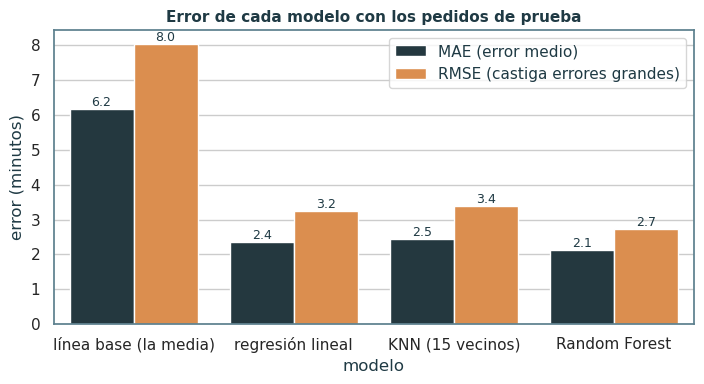

regresión lineal  : MAE 2.36 min (la línea base falla 6.18) -> reduce el error un 62 %
OK · regresión lineal mejora a la línea base
KNN (15 vecinos)  : MAE 2.45 min (la línea base falla 6.18) -> reduce el error un 60 %
OK · KNN (15 vecinos) mejora a la línea base
Random Forest     : MAE 2.13 min (la línea base falla 6.18) -> reduce el error un 66 %
OK · Random Forest mejora a la línea base


In [10]:
display(tabla_notas.rename(index=NOMBRE_LEGIBLE))
display(fig_comparacion)

linea_base_mae = tabla_notas.loc["linea_base_media", "test_mae"]
for nombre in ["regresion_lineal", "knn", "random_forest"]:
    mejora = (1 - tabla_notas.loc[nombre, "test_mae"] / linea_base_mae) * 100
    print(f"{NOMBRE_LEGIBLE[nombre]:18s}: MAE {tabla_notas.loc[nombre, 'test_mae']:.2f} min "
          f"(la línea base falla {linea_base_mae:.2f}) -> reduce el error un {mejora:.0f} %")
    validar(tabla_notas.loc[nombre, "test_mae"] < linea_base_mae, f"{NOMBRE_LEGIBLE[nombre]} mejora a la línea base")

**Qué vemos:**
- **La línea base (decir siempre 25,3 minutos, la media) falla de media 6,2 minutos** (MAE) y su R² es ≈ 0: no explica nada de las diferencias entre pedidos.
- **La regresión lineal baja el error a 2,4 minutos** (MAE) y el RMSE de 8,0 a 3,2. Explica el 84 % de las diferencias entre pedidos (R² = 0,84). Reduce el error en un **62 %** respecto a la línea base.
- **El KNN baja el error a 2,45 minutos** (MAE) y el RMSE a 3,4. Explica el 82 % de las diferencias (R² = 0,82). Reduce el error en un **60 %**: es un poco **peor que la regresión lineal**.
- **El Random Forest baja el error a 2,1 minutos** (MAE) y el RMSE a 2,7. Explica el 88 % de las diferencias (R² = 0,88). Reduce el error en un **66 %**.
- **El Random Forest gana a los otros dos**, sobre todo en el RMSE (2,7 frente a 3,2 y 3,4), lo que indica que **comete menos errores grandes**. La regresión lineal y el KNN quedan bastante cerca entre sí.

**¿Hay sobreajuste?** Comparamos las notas de entrenamiento con las de prueba:
- **Regresión lineal:** casi iguales (MAE 2,31 en entrenamiento y 2,36 en prueba). No memoriza: aprende reglas generales.
- **KNN:** MAE 2,21 en entrenamiento y 2,45 en prueba, una diferencia pequeña. Ojo: al evaluar con los pedidos de entrenamiento, cada pedido se encuentra **a sí mismo** entre sus vecinos, así que esa nota de entrenamiento sale algo optimista.
- **Random Forest:** acierta más con los pedidos que ya conoce (MAE 1,55 en entrenamiento) que con los nuevos (2,13 en prueba). Hay **algo de sobreajuste** (unos 0,6 minutos de diferencia), pero **incluso en la prueba sigue siendo el mejor**, así que no es un problema grave para una primera versión.

---
## 7. Mirando dentro de los modelos

Una nota global no cuenta toda la historia. Miramos **cómo** se equivoca cada modelo.

### 7.1 Predicho frente a real, y errores
**Cómo leer los gráficos de acierto** (arriba): cada pedido de prueba es un punto. **Eje x = minutos reales; eje y = minutos predichos.** La línea discontinua es la predicción perfecta (predicho = real). Cuanto más pegada a la línea esté la nube, mejor. El color dice cuántos pedidos hay en cada zona.

**Cómo leer los histogramas de errores** (abajo): **eje x = error (real − predicho)**; eje y = nº de pedidos. Una campana **estrecha y centrada en 0** es lo ideal. Lo que cae a la derecha de 0 son pedidos en los que el modelo **se quedó corto**.

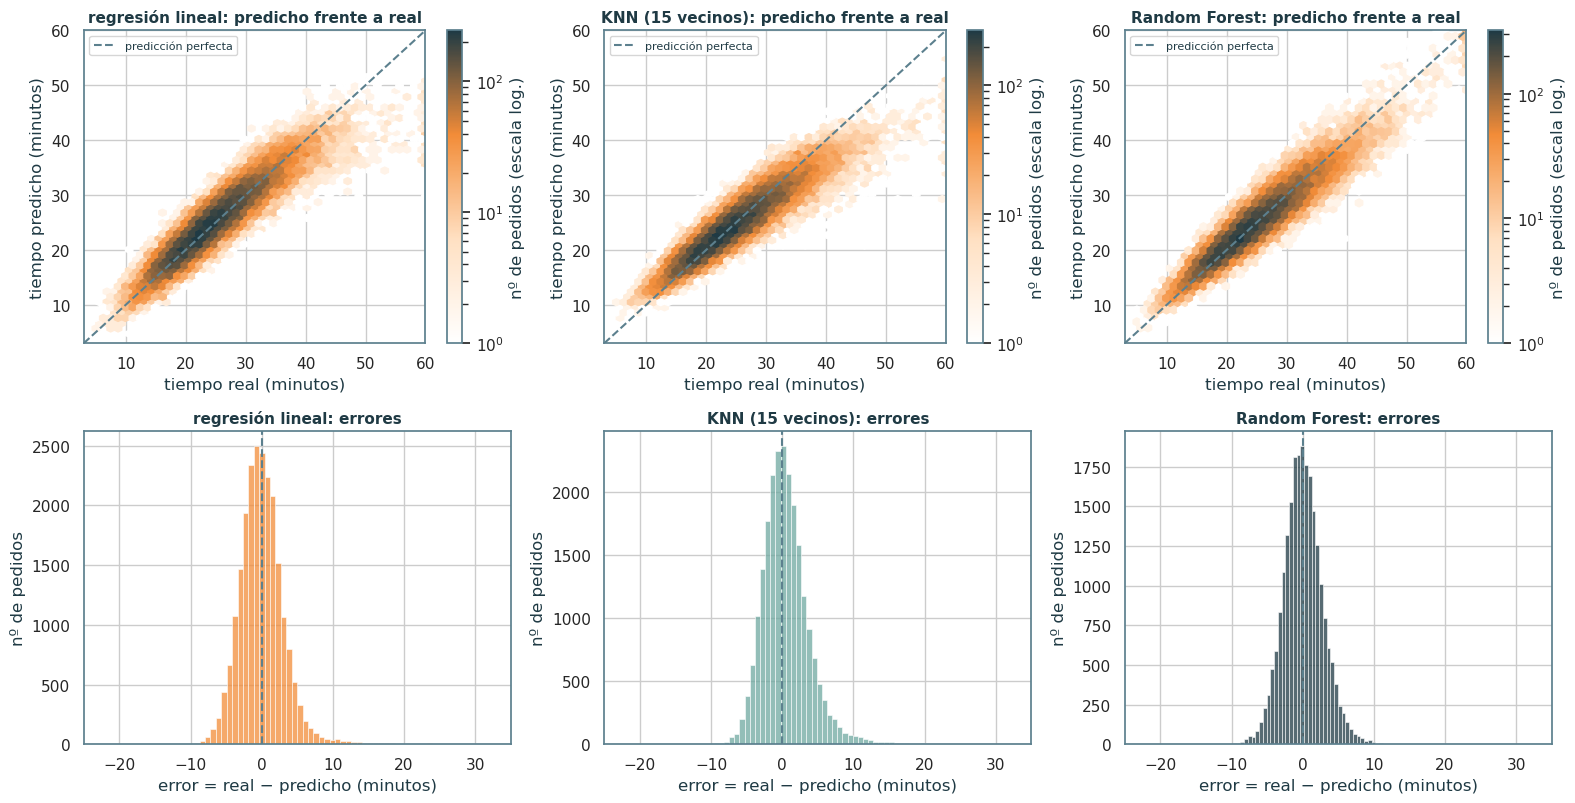

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.2))
for columna, nombre in enumerate(["regresion_lineal", "knn", "random_forest"]):
    pred = resultados[nombre]["pred_prueba"]
    # Gráfico de acierto (arriba)
    ax = axes[0, columna]
    densidad = ax.hexbin(y_prueba, pred, gridsize=45, bins="log", cmap=CMAP_SEC, mincnt=1)
    ax.plot([3, 60], [3, 60], linestyle="--", color=GRIS_AZULADO, label="predicción perfecta")
    ax.set(title=f"{NOMBRE_LEGIBLE[nombre]}: predicho frente a real", xlabel="tiempo real (minutos)",
           ylabel="tiempo predicho (minutos)", xlim=(3, 60), ylim=(3, 60))
    ax.legend(loc="upper left", fontsize=8)
    fig.colorbar(densidad, ax=ax, label="nº de pedidos (escala log.)")
    # Histograma de errores (abajo)
    ax = axes[1, columna]
    sns.histplot(y_prueba.values - pred, bins=60, color=COLOR_MODELO[nombre], ax=ax)
    ax.axvline(0, color=GRIS_AZULADO, linestyle="--")
    ax.set(title=f"{NOMBRE_LEGIBLE[nombre]}: errores", xlabel="error = real − predicho (minutos)", ylabel="nº de pedidos",
           xlim=(-25, 35))
fig.tight_layout()
plt.show()

**Qué vemos:**
- En los **gráficos de acierto**, las tres nubes siguen la línea de predicción perfecta, lo que confirma que los tres modelos aprenden la relación. La del **Random Forest es la más estrecha**: sus predicciones están más cerca de la realidad. La del KNN es la más ancha.
- En los **gráficos de errores**, las tres campanas están **centradas casi en 0**: los modelos no se equivocan sistemáticamente hacia arriba o hacia abajo en general. La del Random Forest es **más estrecha**.
- Pero en los tres gráficos de acierto se ve lo mismo: **en los pedidos muy lentos (a partir de unos 40 minutos reales) los puntos quedan por debajo de la línea**: los modelos **se quedan cortos** con los pedidos más lentos. En los histogramas, es la cola que se alarga hacia la derecha, más larga en el KNN y en la regresión lineal. Lo vemos con números en el siguiente apartado.

### 7.2 ¿Dónde se equivocan más?
Agrupamos los pedidos de prueba según su **tiempo real** (rápidos, normales, lentos) y calculamos el error de cada modelo en cada grupo.

**Cómo leer el gráfico:** eje x = tramo del tiempo real; eje y = MAE en ese tramo. **Barras más bajas = mejor.** La tabla añade el **error medio con signo** (real − predicho): si es positivo, el modelo **se queda corto** en ese tramo.

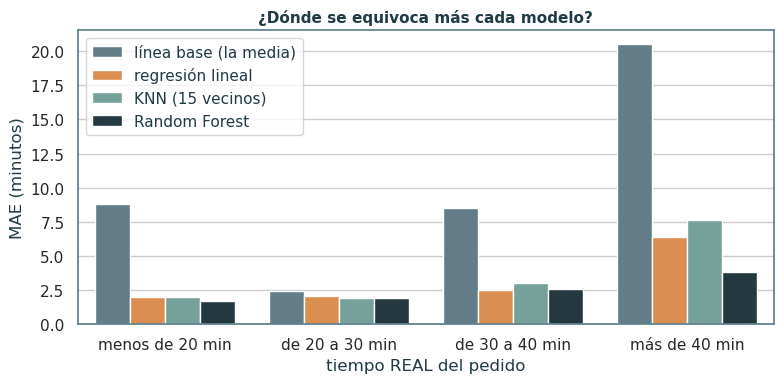


regresión lineal:


,pedidos,mae,error_medio (real − predicho)
tramo,,,
menos de 20 min,5533,1.969,-0.870
de 20 a 30 min,11256,2.085,-0.415
de 30 a 40 min,4716,2.472,0.627
más de 40 min,1158,6.400,5.898



KNN (15 vecinos):


,pedidos,mae,error_medio (real − predicho)
tramo,,,
menos de 20 min,5533,1.981,-1.465
de 20 a 30 min,11256,1.924,0.089
de 30 a 40 min,4716,2.991,2.176
más de 40 min,1158,7.641,7.568



Random Forest:


,pedidos,mae,error_medio (real − predicho)
tramo,,,
menos de 20 min,5533,1.738,-1.007
de 20 a 30 min,11256,1.949,-0.167
de 30 a 40 min,4716,2.582,1.038
más de 40 min,1158,3.855,2.821


In [12]:
display(fig_tramos)
for nombre in ["regresion_lineal", "knn", "random_forest"]:
    print(f"\n{NOMBRE_LEGIBLE[nombre]}:")
    display(resultados[nombre]["tramos"].rename(columns={"error_medio": "error_medio (real − predicho)"}))

**Qué vemos:**
- **En los pedidos normales los tres modelos aciertan bien:** el MAE es de **entre 1,7 y 3 minutos** en los tramos de menos de 20, de 20 a 30 y de 30 a 40 minutos.
- **En los pedidos lentos (más de 40 minutos) es donde fallan más:** la regresión lineal se equivoca de media en **6,4 minutos**, el KNN en **7,6** y el Random Forest en **3,9**. El error medio con signo es positivo (+5,9, +7,6 y +2,8 minutos): los tres **se quedan cortos**, es decir, predicen menos tiempo del que realmente tardó el pedido. El KNN es el que más: al hacer la media de 15 vecinos, **tira de las predicciones hacia el centro**, y hay pocos vecinos realmente lentos.
- **En los pedidos rápidos (menos de 20 minutos) pasa lo contrario:** el error medio es negativo (entre −0,9 y −1,5 minutos), así que los modelos **se pasan un poco**.
- Es un efecto típico de los modelos de regresión: **tienden a acercar sus predicciones a la media**, y los pedidos extremos (muy rápidos o muy lentos) son los más difíciles.
- Solo hay 1.158 pedidos de más de 40 minutos (un 5 % de la prueba) y entre ellos están los pedidos recortados en 60 minutos, cuyo tiempo real pudo ser aún mayor.
- Aquí el **Random Forest gana claramente** a los otros dos; en el resto de tramos están casi empatados (en el de 20 a 30 minutos el KNN es el mejor por poco y en el de 30 a 40 la lineal).

### 7.3 ¿Qué variables usa cada modelo?
**Regresión lineal: los minutos que suma cada variable.** Eje y = variable; eje x = minutos que el modelo **suma** (naranja) o **resta** (azul) por cada unidad más de esa variable. Por ejemplo, un valor de +2,5 en "nº de platos" significa "cada plato más añade 2,5 minutos".
- Las variables 0/1 (como "canal = delivery") se leen como la **diferencia frente a la opción de referencia** (mesa o normal).
- Ojo con `hora del día` y `día de la semana`: la regresión lineal las trata como una **recta**, pero en el notebook 05 vimos que la hora tiene dos picos. Su cifra es solo una media aproximada.

**Importancia por permutación (los tres modelos):** eje y = variable; eje x = **cuántos minutos empeora el MAE** si desordenamos esa variable al azar. Cuanto más empeora, más depende el modelo de ella.

Tiempo "base" de la regresión lineal (todo a 0): 13.8 min


,minutos
variable,
canal = delivery (frente a mesa),3.600
ingrediente agotado,3.480
nº de platos,1.920
canal = takeaway (frente a mesa),1.260
complejidad del pedido,1.220
pedidos en cola,1.120
nº de platos complejos,0.880
lluvia (mm),0.030
hora del día,0.010


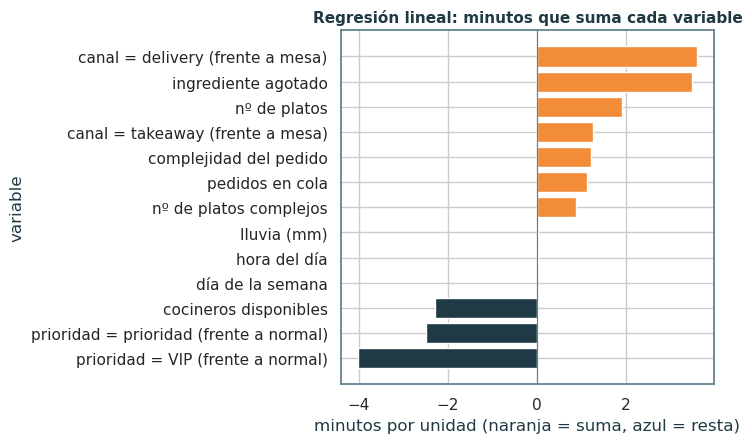

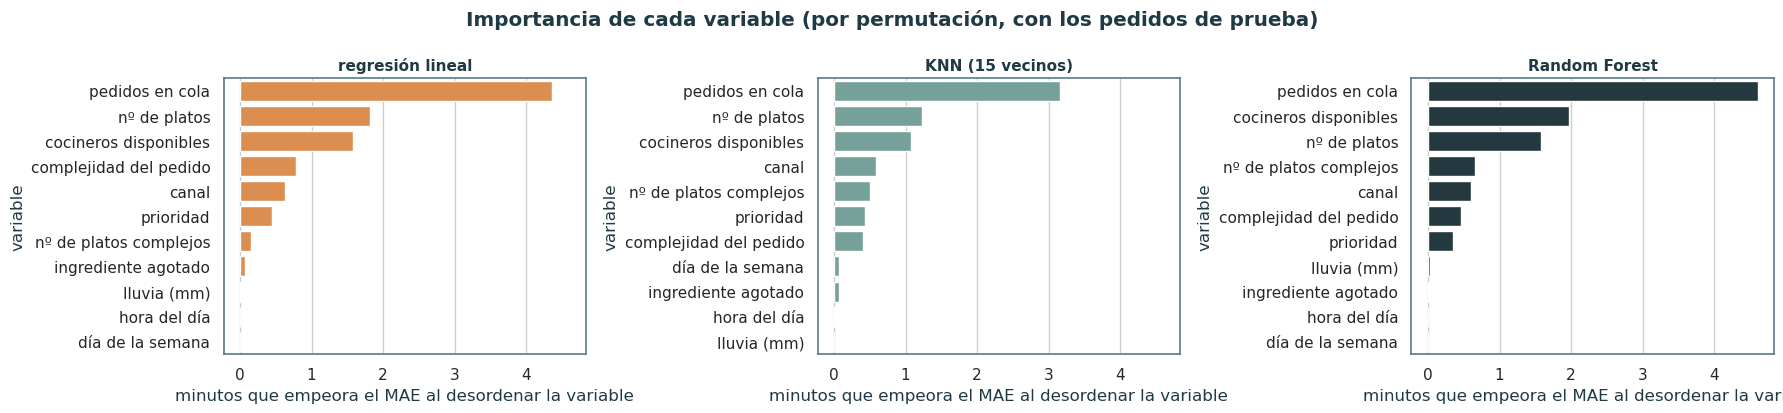

In [13]:
coeficientes = resultados["regresion_lineal"]["coeficientes"]
intercepto = resultados["regresion_lineal"]["pipeline"].named_steps["modelo"].intercept_
print(f"Tiempo \"base\" de la regresión lineal (todo a 0): {intercepto:.1f} min")
display(coeficientes.sort_values("minutos", ascending=False).round(2).set_index("variable"))

fig = figura_coeficientes(coeficientes.sort_values("minutos", ascending=False))
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharex=True)
for ax, nombre in zip(axes, ["regresion_lineal", "knn", "random_forest"]):
    sns.barplot(data=resultados[nombre]["importancia"], y="variable", x="empeora_mae_min", color=COLOR_MODELO[nombre], ax=ax)
    ax.set(title=NOMBRE_LEGIBLE[nombre], xlabel="minutos que empeora el MAE al desordenar la variable", ylabel="variable")
fig.suptitle("Importancia de cada variable (por permutación, con los pedidos de prueba)", fontweight="bold", color=AZUL)
fig.tight_layout()
plt.show()

**Qué vemos:**

**Regresión lineal (los minutos que suma cada variable):**
- El pedido "base" (todo a 0) son unos **14 minutos**, y a partir de ahí se suma o se resta.
- **Suman:** ser **delivery** (+3,6 min frente a mesa), tener un **ingrediente agotado** (+3,5), **cada plato** (+1,9), ser takeaway (+1,3), **cada punto de complejidad** (+1,2), **cada pedido en cola** (+1,1) y **cada plato complejo** (+0,9).
- **Restan:** ser pedido **VIP** (−4,0 min frente a normal), tener **prioridad** (−2,5) y **cada cocinero más** (−2,3 min **con la misma cola**). Esto confirma lo que sospechábamos en el notebook 05: más cocineros sí reducen el tiempo cuando se compara con la misma cola.
- **La hora del día, el día de la semana y la lluvia aparecen casi en 0:** su efecto ya lo recoge la cola de pedidos (ver más abajo).

**Importancia por permutación (los tres modelos coinciden en lo esencial):**
- **Lo más importante, con diferencia, es `pedidos en cola`:** desordenarla empeora el MAE en unos **3,2 a 4,6 minutos** (menos en el KNN, que reparte el peso entre más variables).
- Después vienen **`cocineros disponibles`** y **`nº de platos`** (entre 1,1 y 2,0 minutos), y más abajo la complejidad del pedido, los platos complejos, el canal y la prioridad.
- **La hora del día y el día de la semana no aportan casi nada** a ninguno de los tres modelos. No es que no importen: en el notebook 05 vimos que a esas horas y esos días hay más cola, y **la cola ya recoge ese efecto**. Lo mismo pasa, en menor medida, con la lluvia y con los ingredientes agotados (que son pocos pedidos).

---
## 8. Elegir el mejor y registrarlo

**Qué hacemos:** elegimos el modelo con **menor RMSE en la prueba** (castiga los errores grandes, que son los que más molestan en la cocina) entre la regresión lineal, el KNN y el Random Forest, y lo **registramos** en el *Model Registry* de MLflow con el nombre `smart_restaurant_regresion_tiempo_prep` y el alias `actual`.

**Qué es el Model Registry:** la "estantería" donde MLflow guarda los modelos con **nombre y versión**. Cada vez que se ejecuta el notebook se crea una **versión nueva** (con la **fecha y hora** de entrenamiento en su descripción y en la etiqueta `fecha_ejecucion`), y el alias `actual` pasa a apuntar a la última. Así, cualquiera puede cargar "el modelo actual" sin saber en qué ejecución se entrenó.

**Una advertencia honesta:** comparamos solo tres modelos con ajustes fijos, así que usamos los pedidos de prueba para elegir. Si más adelante ajustáramos parámetros, habría que separar una **tercera parte (validación)** para elegir, y dejar la prueba solo para el examen final.

In [14]:
# Elegimos el mejor entre los tres modelos "de verdad" (la línea base no cuenta como candidata)
candidatos = ["regresion_lineal", "knn", "random_forest"]
mejor = min(candidatos, key=lambda n: resultados[n]["metricas"]["test_rmse"])
ganador = resultados[mejor]
print(f"Mejor modelo: {NOMBRE_LEGIBLE[mejor]} (RMSE en prueba = {ganador['metricas']['test_rmse']:.2f} min, MAE = {ganador['metricas']['test_mae']:.2f} min)")

# Lo registramos en el Model Registry: crea una versión nueva del modelo
version = mlflow.register_model(ganador["uri_modelo"], NOMBRE_MODELO)
cliente = MlflowClient()
cliente.set_registered_model_alias(NOMBRE_MODELO, ALIAS_MODELO, version.version)       # el alias apunta a esta versión
cliente.update_model_version(
    NOMBRE_MODELO, version.version,
    description=(f"{NOMBRE_LEGIBLE[mejor]}. Entrenado el {MARCA_TIEMPO} con pedidos hasta {entrenamiento['fecha'].max():%d-%m-%Y}. "
                 f"En prueba: MAE {ganador['metricas']['test_mae']:.2f} min, RMSE {ganador['metricas']['test_rmse']:.2f} min, "
                 f"R2 {ganador['metricas']['test_r2']:.3f}."))
cliente.set_model_version_tag(NOMBRE_MODELO, version.version, "fecha_ejecucion", MARCA_TIEMPO)   # fecha y hora de esta versión
cliente.set_model_version_tag(NOMBRE_MODELO, version.version, "modelo", NOMBRE_LEGIBLE[mejor])
cliente.set_tag(ganador["run_id"], "registrado_como", f"{NOMBRE_MODELO} v{version.version}")
print(f"Modelo '{NOMBRE_MODELO}' registrado: versión {version.version}, alias '{ALIAS_MODELO}'.")

Registered model 'smart_restaurant_regresion_tiempo_prep' already exists. Creating a new version of this model...
2026/11/25 08:57:24 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: smart_restaurant_regresion_tiempo_prep, version 2


Mejor modelo: Random Forest (RMSE en prueba = 2.73 min, MAE = 2.13 min)
Modelo 'smart_restaurant_regresion_tiempo_prep' registrado: versión 2, alias 'actual'.


Created version '2' of model 'smart_restaurant_regresion_tiempo_prep'.


**Comprobamos que el modelo guardado funciona:** guardar no basta; hay que **recuperarlo** y ver que da lo mismo. Lo cargamos desde MLflow por su nombre y su alias (`models:/nombre@alias`), le pasamos los pedidos de prueba y comprobamos que las predicciones **coinciden** con las del modelo que acabamos de entrenar. Después lo probamos con un **pedido inventado**.

In [15]:
# Recuperamos el modelo desde MLflow, igual que lo haría otra persona o otro notebook
modelo_cargado = mlflow.sklearn.load_model(f"models:/{NOMBRE_MODELO}@{ALIAS_MODELO}")

predicciones_cargado = modelo_cargado.predict(X_prueba)
validar(bool(np.allclose(predicciones_cargado, ganador["pred_prueba"])), "el modelo recuperado de MLflow da las mismas predicciones que el entrenado")

# Un pedido inventado: 3 platos (1 complejo), 8 pedidos en cola y 5 cocineros, sábado a las 20:30, delivery, prioridad normal
pedido_nuevo = pd.DataFrame([{
    "n_platos": 3, "num_platos_complejos": 1, "complejidad_pedido": 4.5, "cola_pedidos": 8, "cocineros_disponibles": 5,
    "precipitacion_mm": 0.0, "hora_dec": 20.5, "dia_semana": 6, "ingrediente_agotado": 0,
    "canal": "delivery", "prioridad_aux": "normal"}])[VARIABLES]
print(f"Pedido nuevo -> tiempo estimado: {modelo_cargado.predict(pedido_nuevo)[0]:.1f} minutos")

# Mismo pedido pero con la cocina saturada (20 pedidos en cola, 3 cocineros): ¿cambia la estimación?
pedido_saturado = pedido_nuevo.assign(cola_pedidos=20, cocineros_disponibles=3)
print(f"Con la cocina saturada (20 en cola y 3 cocineros) -> {modelo_cargado.predict(pedido_saturado)[0]:.1f} minutos")

OK · el modelo recuperado de MLflow da las mismas predicciones que el entrenado
Pedido nuevo -> tiempo estimado: 25.7 minutos
Con la cocina saturada (20 en cola y 3 cocineros) -> 56.5 minutos


---
## 9. Cómo verlo en MLflow

Abre **http://localhost:5000** en el navegador:

1. **Experiments → `smart-restaurant-regresion-tiempo-prep`.** Cada `comparacion_modelos_<fecha>_<hora>` tiene dentro sus 3 pruebas hijas (`regresion_lineal_…`, `knn_…`, `random_forest_…`; pulsa la flecha para desplegarlas). La fecha y la hora son las de la ejecución del notebook, así se distinguen las ejecuciones. Las notas de la línea base están en la ejecución padre (métricas `linea_base_…`).
2. **Comparar pruebas:** marca las tres hijas y pulsa **Compare**. Se ven los parámetros y las métricas (`train_…` y `test_…`) lado a lado.
3. **Abrir una prueba:** en la pestaña **Artifacts** están los gráficos (`real_vs_predicho.png`, `errores.png`, `importancia_permutacion.png`), las tablas en CSV y el modelo. En la ejecución padre están los gráficos que comparan los tres modelos.
4. **Models → `smart_restaurant_regresion_tiempo_prep`:** las versiones del modelo registrado, la fecha y hora de entrenamiento de cada una (en su descripción) y cuál tiene el alias `actual`.

**Nota:** los enlaces que imprime MLflow en las celdas (`http://mlflow:5000/...`) solo funcionan dentro de Docker. En el navegador, cambia `mlflow` por `localhost`.

---
## 10. Conclusiones

### 10.1 Qué hemos hecho
- Hemos construido el **primer modelo del objetivo 2**: predecir los minutos que tardará en prepararse un pedido, **usando las variables tal cual** (sin crear ninguna nueva), con el único cambio de pasar `canal` y `prioridad_aux` a columnas 0/1.
- Hemos entrenado con los pedidos más antiguos (hasta el 04-06-2025) y examinado con los más recientes (desde el 05-06-2025): **22.663 pedidos que el modelo no había visto**.
- Hemos comparado **tres modelos** (regresión lineal, KNN y Random Forest) con una **línea base** (predecir siempre la media), y todo está **registrado en MLflow** (parámetros, métricas, gráficos y modelos), con la **fecha y hora** de cada ejecución y de cada versión del modelo.

### 10.2 Resultados (pedidos de prueba)
| Modelo | MAE (min) | RMSE (min) | R² |
|---|---|---|---|
| Línea base (siempre la media, 25,3 min) | 6,18 | 8,02 | −0,00 |
| Regresión lineal | 2,36 | 3,25 | 0,84 |
| KNN (15 vecinos) | 2,45 | 3,40 | 0,82 |
| **Random Forest** | **2,13** | **2,73** | **0,88** |

El **Random Forest** es el modelo elegido y el que queda registrado con el alias `actual`.

### 10.3 Qué hemos aprendido
- **Se puede predecir bien el tiempo de preparación con los datos que ya tenemos:** el mejor modelo se equivoca de media **2,1 minutos**, frente a los 6,2 de la línea base (un **66 % menos** de error).
- **Lo que más pesa es la cola de pedidos**, seguida de los cocineros y del número de platos. Es decir, **el tiempo depende sobre todo de cuánta carga tiene la cocina**.
- **La regresión lineal ya funciona muy bien** (R² = 0,84) y es fácil de explicar: cada plato suma unos 2 minutos, cada pedido en cola algo más de 1, y cada cocinero más resta unos 2 minutos. El Random Forest mejora, sobre todo en los pedidos lentos, porque capta curvas y combinaciones sin que se lo tengamos que explicar.
- **El KNN funciona casi tan bien como la regresión lineal** (R² = 0,82), con una idea muy intuitiva: "pedidos parecidos tardan parecido". Pero necesita **escalar las variables**, es **más lento al predecir** (compara con todos los pedidos guardados) y es **el que peor trata los pedidos muy lentos** (por hacer la media de vecinos). Con otro número de vecinos podría cambiar algo; aquí no lo hemos ajustado.
- **Los pedidos muy lentos (más de 40 minutos) son los más difíciles:** los tres modelos se quedan cortos con ellos.
- **El Random Forest tiene algo de sobreajuste** (acierta más con los pedidos que ya conoce), pero sigue siendo el mejor con los pedidos nuevos.

### 10.4 Limitaciones (importante tenerlas claras)
- **Datos sintéticos:** las relaciones de los datos son más limpias y regulares que en un restaurante real, así que **en la realidad el error sería mayor**.
- **Tope de 60 minutos y de 20 pedidos en cola:** son valores recortados en los datos; el tiempo real de algunos pedidos pudo ser mayor.
- **La prueba solo cubre de junio a diciembre de 2025.** No sabemos cómo se comporta el modelo de enero a mayo.
- **El modelo no sirve para los lunes:** el restaurante está cerrado y no hay datos de ese día.
- **Elegimos el modelo con los pedidos de prueba.** Con solo tres modelos y sin ajustar parámetros el efecto es pequeño, pero si más adelante se ajustan parámetros hay que separar una **tercera parte (validación)** para elegir.
- **`ingrediente_agotado`:** sigue pendiente confirmar con el equipo que este dato se conoce **cuando entra el pedido**. Si solo se supiera al empezar a cocinar, habría que quitarlo (el modelo apenas lo usa, así que el cambio sería pequeño).

### 10.5 Posibles mejoras futuras
Quedan fuera de este primer modelo a propósito:
- Combinar la cola con los cocineros en una sola variable (cuántos pedidos esperan por cocinero).
- Ajustar los parámetros del Random Forest y el número de vecinos del KNN, o probar otros modelos de árboles (por ejemplo *Gradient Boosting*), con una parte de validación aparte.
- Tratar de forma especial los pedidos lentos, que son los que peor se predicen.
- Usar el modelo registrado (`models:/smart_restaurant_regresion_tiempo_prep@actual`) desde una **API** o desde el **dashboard** para estimar el tiempo de cada pedido nuevo.